In [1]:
from pathlib import Path
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from IPython.display import clear_output

/opt/conda/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/conda/lib/python3.10/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


In [2]:
device= "cuda" if torch.cuda.is_available() else "cpu"
image_size=32
batch_size=64
project_folder=Path("..") if Path.cwd().name== " notebooks" else Path(".")
data=project_folder/"data"
outputs= project_folder/"outputs"
data.mkdir(exist_ok=True)
outputs.mkdir(exist_ok= True)

In [3]:
transforming_seq= transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

train_set= datasets.MNIST(
    root=data, train=True, download= True, transform = transforming_seq,
)
test_set=datasets.MNIST(
    root=data, train=False, download= True, transform= transforming_seq,
)

train_loader= DataLoader(train_set, batch_size=batch_size, shuffle= True)
test_loader= DataLoader(test_set, batch_size, shuffle= False)

x, labels= next(iter(train_loader))
x_test, labels_test= next(iter(test_loader))

In [4]:
import sys
project_root= Path.cwd().parent
sys.path.append(str(project_root))

In [ ]:
import ddpm.models.unet_with_resblocks as unet_res
import ddpm.masks as masks
import importlib
importlib.reload(masks)

<module 'utils.masks' from '/home/islem.dhouioui/ddpm/utils/masks.py'>

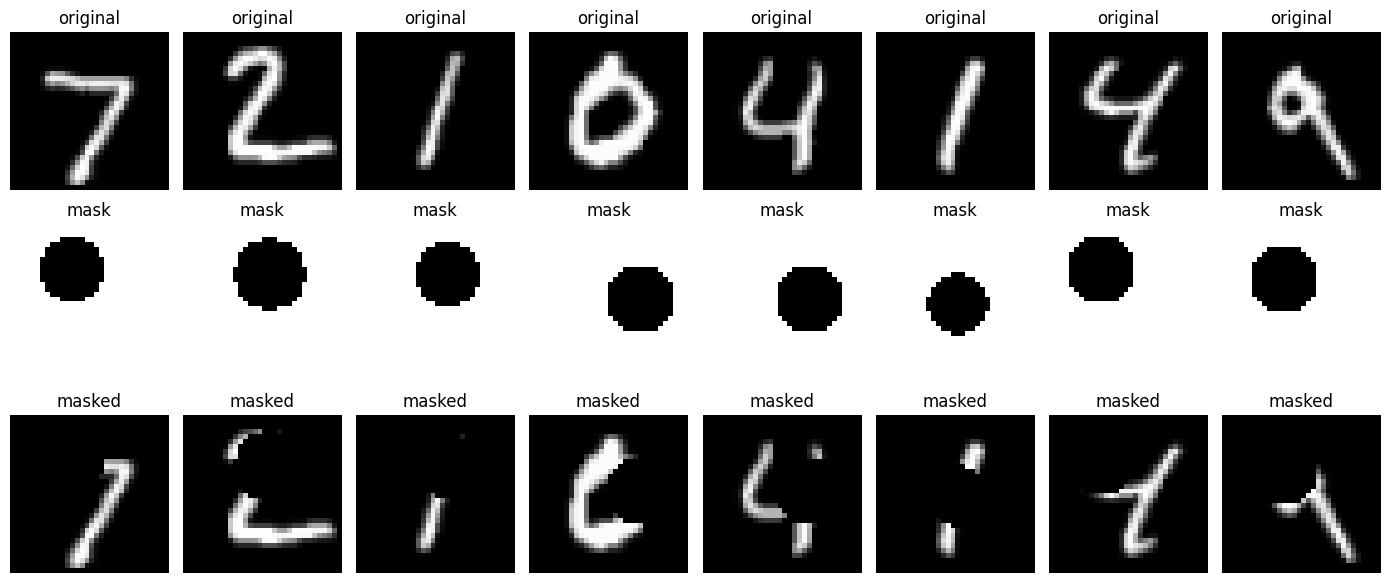

In [ ]:
from ddpm.masks import random_circle_mask
x_test=x_test.to(device)
masks= random_circle_mask(x_test,min_radius=6.0, max_radius=8.0, min_pixel_value=0.5)
y=x_test*masks

num_images = min(8, x_test.shape[0])

fig, axes = plt.subplots(3, num_images, figsize=(14, 6))

for i in range(num_images):
    axes[0, i].imshow(x_test[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[0, i].set_title("original")

    axes[1, i].imshow(masks[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
    axes[1, i].set_title("mask")

    axes[2, i].imshow(y[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[2, i].axis("off")
    axes[2, i].set_title("masked")

plt.tight_layout()
plt.show()

In [7]:
importlib.reload(unet_res)
UNetWithResBlocks= unet_res.UNetRes
model_unet= UNetWithResBlocks(2,1,64,(1,2,4),2,0.1).to(device)

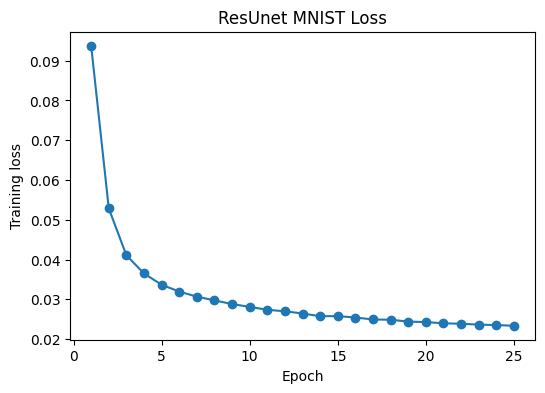

In [21]:
model_unet= model_unet.to(device)
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_unet_path=checkpoints/"resunet_model.pth"
loss_plot_path=checkpoints/"resunet_model_loss.png"

optimizer= torch.optim.Adam(model_unet.parameters(), lr=1e-3)
mse= nn.MSELoss(reduction="none")
epochs= 25 #30 #40 
train_losses=[]
start_epoch=0

if model_unet_path.exists():
    checkpoint = torch.load(model_unet_path,map_location=device)
    if "model_unet" in checkpoint:
        model_unet.load_state_dict(checkpoint["model_unet"])
    if "optimizer" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer"])
    train_losses= checkpoint.get("train_losses", [])
    start_epoch=checkpoint.get("completed_epochs", len(train_losses)) 


for epoch in range(start_epoch, epochs):
    model_unet.train()
    epoch_loss= 0.0
    for batch in tqdm(train_loader, desc=f"Epoch{epoch+1}/{epochs}"):
        x=batch[0].to(device)
        masks= random_circle_mask(x,min_radius=6.0, max_radius=8.0, min_pixel_value=0.5)
        y=x*masks
        A_inv= model_unet(y,masks)
        missing_region= 1-masks


        pixel_loss= mse(A_inv, x)
        weight= 1.0 +20.0*x
        weighted_missing=missing_region*weight
        loss= (pixel_loss*weighted_missing).sum()/weighted_missing.sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader)
    train_losses.append(avg_loss)
    #print(f"Epoch{epoch+1}/{epoch}-loss: {avg_loss: .6f}")
    torch.save({
    "model_unet": model_unet.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
                  "completed_epochs": epoch+1,
     }, model_unet_path)
    
    clear_output(wait=True)
    plt.figure(figsize=(6,4))
    plt.plot(range(1,len(train_losses)+1), train_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Training loss")
    plt.title("ResUnet MNIST Loss")
    plt.savefig(loss_plot_path)
    plt.show()

In [28]:
model_unet.eval()
with torch.no_grad():
    x_test,_=next(iter(test_loader))
    x_test=x_test.to(device)
    num_images=8
    x1=x_test[:num_images]
    masks= random_circle_mask(x1,min_radius=6.0, max_radius=8.0, min_pixel_value=0.5)
    y1=x1*masks
    reconstructed= model_unet(y1,masks)

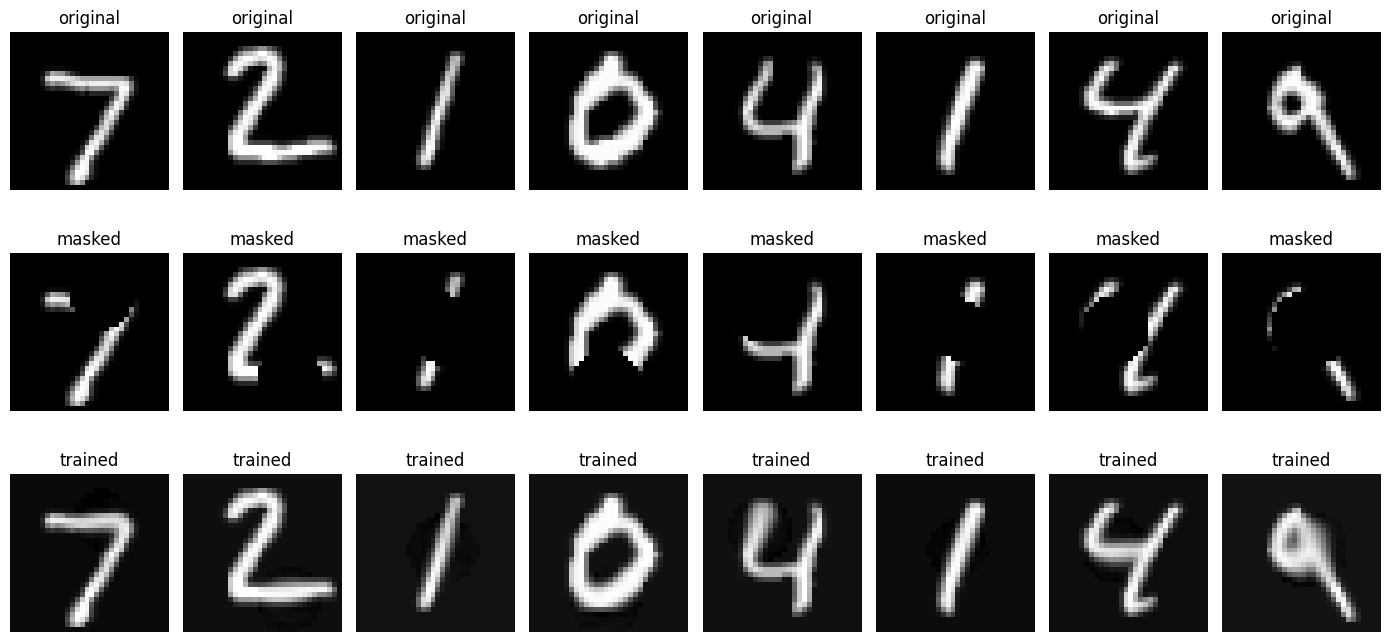

In [29]:
fig, axes= plt.subplots(3, num_images, figsize=(14,7))
for i in range (num_images):
    axes[0,i].imshow(x1[i,0].detach().cpu(), cmap="gray")
    axes[0,i].axis("off")
    axes[0,i].set_title("original")
    axes[1,i].imshow(y1[i,0].detach().cpu(), cmap="gray")
    axes[1,i].axis("off")
    axes[1,i].set_title("masked")
    axes[2,i].imshow(reconstructed[i,0].detach().cpu(), cmap="gray")
    axes[2,i].axis("off")
    axes[2,i].set_title("trained")
plt.tight_layout()
plt.show()

In [ ]:
import ddpm.diffusion.noise_scheduler as noise
importlib.reload(noise)
scheduler= noise.LinearNoiseScheduler(timesteps=1000, beta_start=1e-4, beta_end=0.02,device=device)

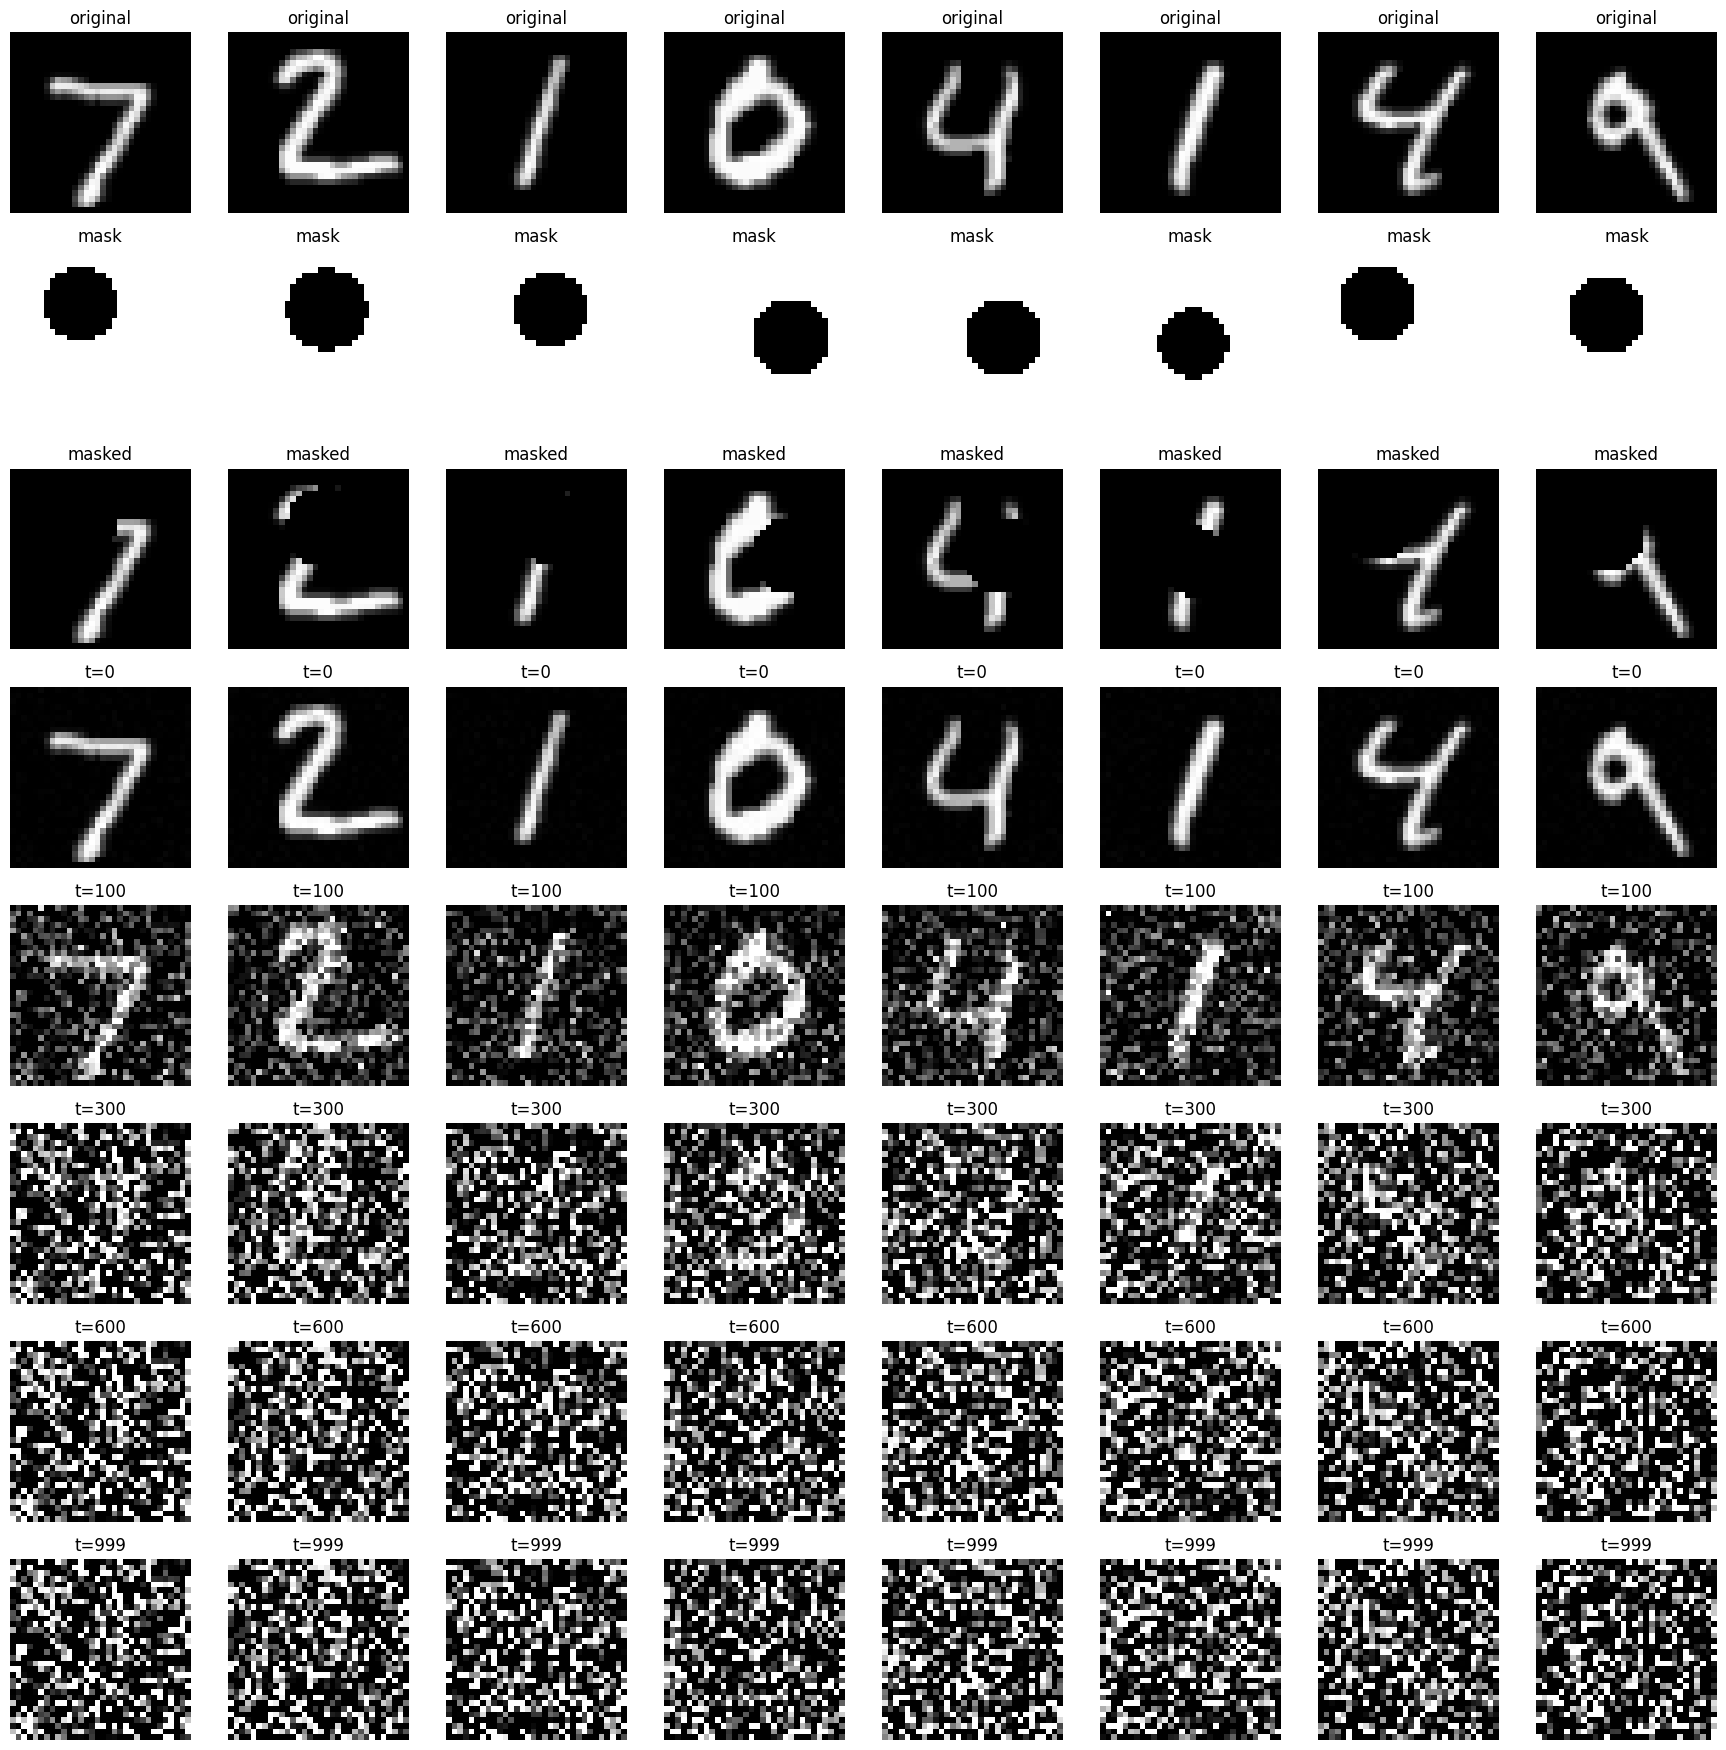

In [9]:
epsilon= torch.randn_like(x_test)
timesteps_shown= [0,100,300,600,999]
num_rows=3+len(timesteps_shown)

fig1, axes1 = plt.subplots(num_rows,num_images, figsize=(2.2*num_images, 2.2*num_rows))


for i in range(num_images):
    axes1[0, i].imshow(x_test[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes1[0, i].axis("off")
    axes1[0, i].set_title("original")

    axes1[1, i].imshow(masks[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes1[1, i].axis("off")
    axes1[1, i].set_title("mask")

    axes1[2, i].imshow(y[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes1[2, i].axis("off")
    axes1[2, i].set_title("masked")
    for j , timestep in enumerate(timesteps_shown):
        t=torch.full((x_test.shape[0],),timestep,device=device).long()
        xt=scheduler.add_noise(x0=x_test, epsilon=epsilon,t=t)
        axes1[3+j,i].imshow(xt[i,0].detach().cpu(),cmap="gray",vmin=0,vmax=1)
        axes1[3+j, i].axis("off")
        axes1[3+j, i].set_title(f"t={timestep}")
plt.tight_layout()
plt.show()        

In [ ]:
import ddpm.models.unet_with_temb as unet_ddpm
importlib.reload(unet_ddpm)
UNetDDPM= unet_ddpm.DDPM
model_ddpm_repaint= UNetDDPM(1,1,64,(1,2,4),2,0.1)
model_ddpm_repaint= model_ddpm_repaint.to(device)

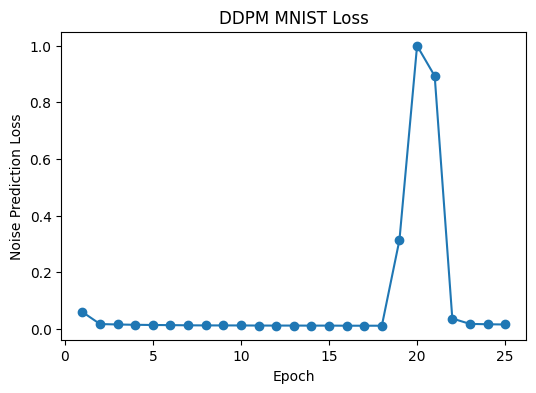

In [12]:
model_ddpm_repaint= model_ddpm_repaint.to(device)
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_ddpm_path=checkpoints/"ddpm_repaint_model.pth"
loss_plot_path=checkpoints/"ddpm_repaint_model_loss.png"

optimizer= torch.optim.Adam(model_ddpm_repaint.parameters(), lr=1e-3)

epochs= 25 #30 #40 
train_losses=[]
start_epoch=0

if model_ddpm_path.exists():
    checkpoint = torch.load(model_ddpm_path,map_location=device)
    if "model_ddpm_repaint" in checkpoint:
        model_ddpm_repaint.load_state_dict(checkpoint["model_ddpm_repaint"])
    if "optimizer" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer"])
    train_losses= checkpoint.get("train_losses", [])
    start_epoch=checkpoint.get("completed_epochs", len(train_losses)) 


for epoch in range(start_epoch, epochs):
    model_ddpm_repaint.train()
    epoch_loss= 0.0
    for batch in tqdm(train_loader, desc=f"Epoch{epoch+1}/{epochs}"):
        x=batch[0].to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction=model_ddpm_repaint(xt,t)
        
        loss=((noise_prediction -epsilon)**2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader)
    train_losses.append(avg_loss)
    #print(f"Epoch{epoch+1}/{epoch}-loss: {avg_loss: .6f}")
    torch.save({
    "model_ddpm_repaint": model_ddpm_repaint.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
                  "completed_epochs": epoch+1,
     }, model_ddpm_path)
    
    clear_output(wait=True)
    plt.figure(figsize=(6,4))
    plt.plot(range(1,len(train_losses)+1), train_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Noise Prediction Loss")
    plt.title("DDPM MNIST Loss")
    plt.savefig(loss_plot_path)
    plt.show()

In [24]:
def sample(model,scheduler,x0,masks):
    with torch.no_grad():
        model.eval()
        B=x0.shape[0]
        device=x0.device
        timesteps=scheduler.betas.shape[0]
        xt=masks*x0+(1.0-masks)*torch.randn_like(x0)
        for step in reversed(range(timesteps)):
            t=torch.full((B,),step,device=device,dtype=torch.long)
            predicted_noise=model(xt,masks,t)
            xt_prev,x0_pred=scheduler.reverse_sampling_step(
                xt,x0,predicted_noise,step,masks
            )
            xt=xt_prev
        reconstruction=masks*x0+(1.0-masks)*xt
        return reconstruction.clamp(0.0,1.0)

In [12]:
model_ddpm_path= Path("checkpoints")/"ddpm_repaint_model.pth"
ddpm_checkpoint=torch.load(model_ddpm_path,map_location=device)
model_ddpm_repaint.load_state_dict(ddpm_checkpoint["model_ddpm_repaint"])

<All keys matched successfully>

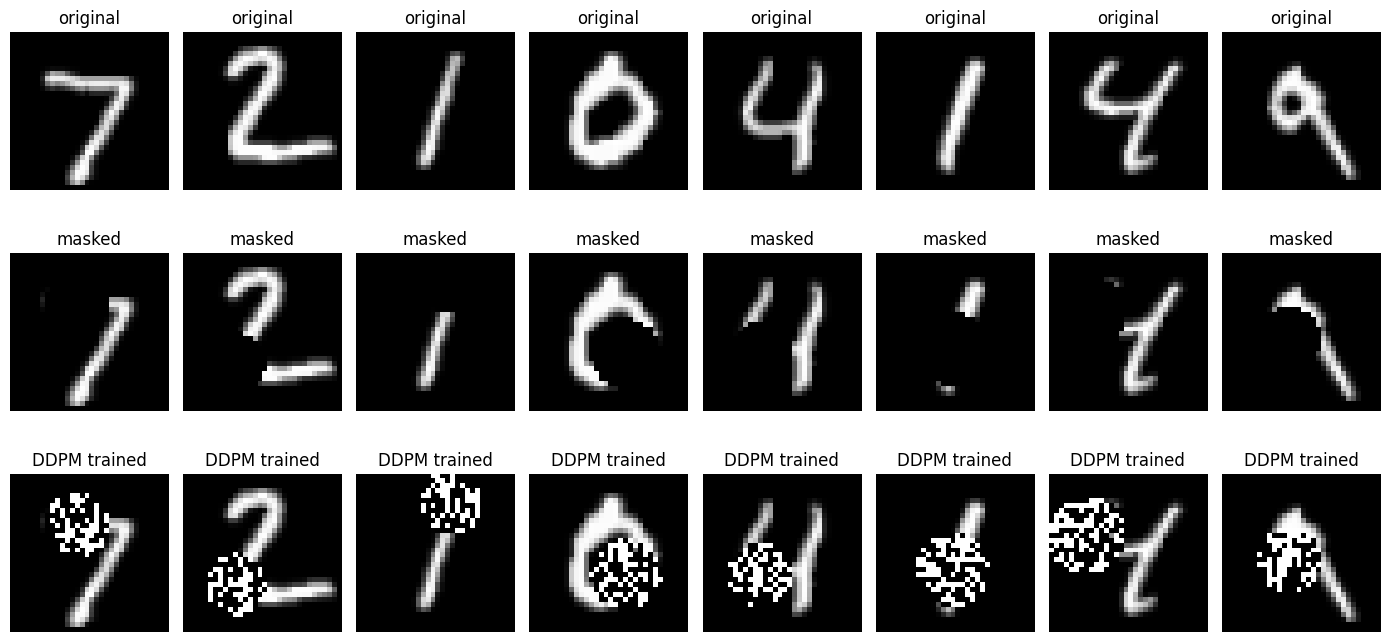

In [ ]:
model_ddpm_repaint.eval()
x_test,_=next(iter(test_loader))
x_test=x_test.to(device)
num_images=8
x2=x_test[:num_images]
masks= random_circle_mask(x2,min_radius=6.0, max_radius=8.0, min_pixel_value=0.5)
y2=x2*masks
reconstruction=sample(model_ddpm_repaint,scheduler,x2,masks)
fig, axes= plt.subplots(3, num_images, figsize=(14,7))
for i in range (num_images):
    axes[0,i].imshow(x2[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1)
    axes[0,i].axis("off")
    axes[0,i].set_title("original")
    axes[1,i].imshow(y2[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1)
    axes[1,i].axis("off")
    axes[1,i].set_title("masked")
    axes[2,i].imshow(reconstruction[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1)
    axes[2,i].axis("off")
    axes[2,i].set_title("DDPM trained")
plt.tight_layout()
plt.show()

In [13]:
def sample_ddpm(model,scheduler,x0):
    with torch.no_grad():
        model.eval()
        timesteps= scheduler.betas.shape[0]
        B=x0.shape[0]
        xt= torch.randn_like(x0)
        for step in reversed(range(timesteps)):
            t=torch.full((B,),step,device=device,dtype=torch.long)
            predicted_noise=model(xt,t)
            xt,x0_pred=scheduler.reverse_sampling_step(
                xt,predicted_noise,step
            )
        return xt.clamp(0.0,1.0) 

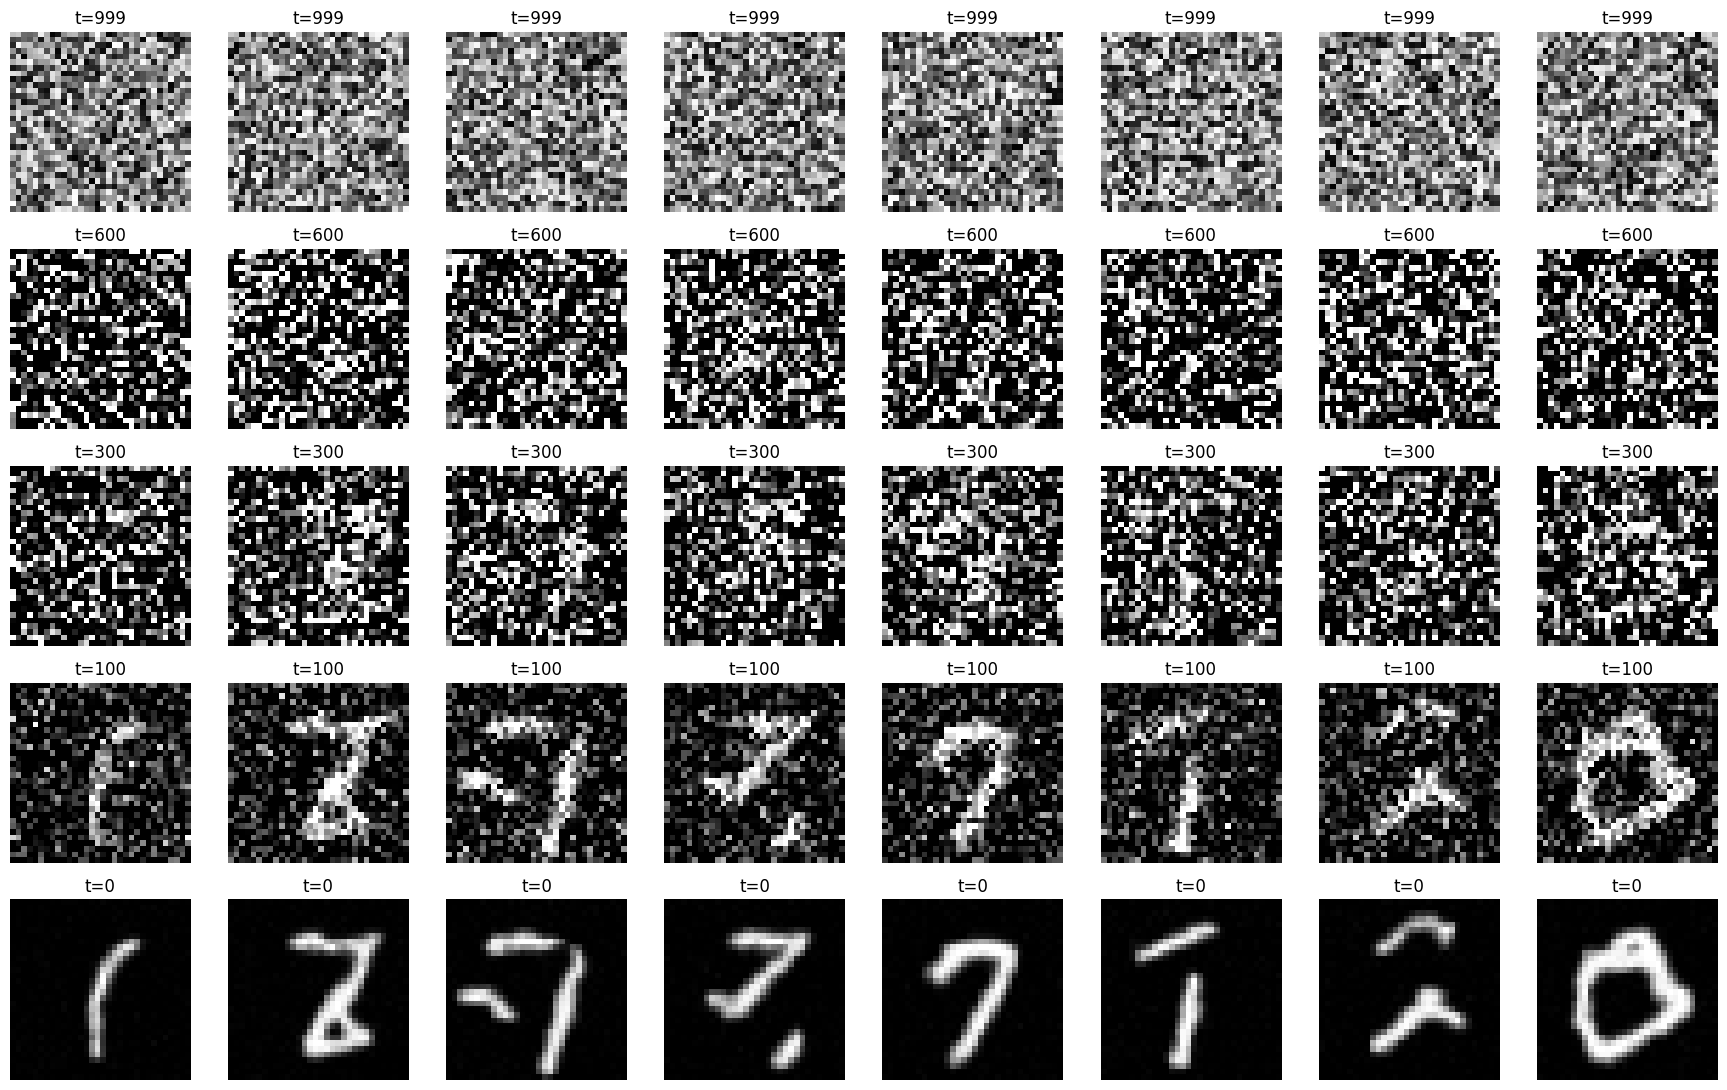

In [20]:
model_ddpm_repaint.eval()
x_test,_=next(iter(test_loader))
x_test=x_test.to(device)
num_images=8
x3=x_test[:num_images]
timesteps_reverse_shown= [999,600,300,100,0]
num_rows=len(timesteps_reverse_shown)

fig2, axes2 = plt.subplots(num_rows,num_images, figsize=(2.2*num_images, 2.2*num_rows))

with torch.no_grad():
    xt=torch.rand_like(x3)

    for step in reversed(range(scheduler.betas.shape[0])):
        if step in timesteps_reverse_shown:
            row= timesteps_reverse_shown.index(step)
            for i in range(num_images):
                axes2[row,i].imshow(xt[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1) 
                axes2[row,i].axis("off")
                axes2[row,i].set_title(f"t={step}")
        t=torch.full((x3.shape[0],),step, device=device, dtype= torch.long)
        predicted_noise=model_ddpm_repaint(xt,t)
        xt,x0_predicted=scheduler.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()              

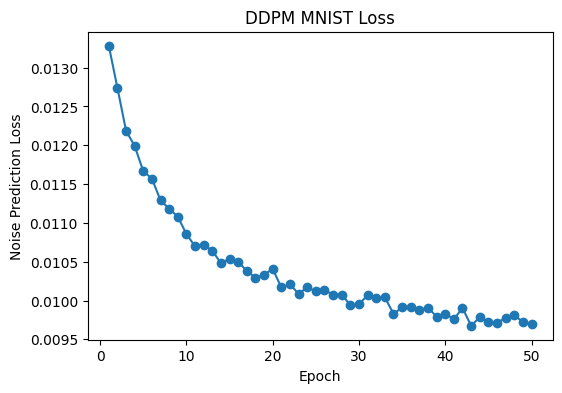

In [21]:
model_ddpm_repaint= model_ddpm_repaint.to(device)
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_ddpm_path=checkpoints/"ddpm_repaint_model1.pth"
loss_plot_path=checkpoints/"ddpm_repaint_model_1loss.png"

optimizer= torch.optim.Adam(model_ddpm_repaint.parameters(), lr=1e-4)

epochs= 50  
train_losses=[]
start_epoch=0

if model_ddpm_path.exists():
    checkpoint = torch.load(model_ddpm_path,map_location=device)
    if "model_ddpm_repaint" in checkpoint:
        model_ddpm_repaint.load_state_dict(checkpoint["model_ddpm_repaint"])
    if "optimizer" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer"])
    train_losses= checkpoint.get("train_losses", [])
    start_epoch=checkpoint.get("completed_epochs", len(train_losses)) 


for epoch in range(start_epoch, epochs):
    model_ddpm_repaint.train()
    epoch_loss= 0.0
    for batch in tqdm(train_loader, desc=f"Epoch{epoch+1}/{epochs}"):
        x=batch[0].to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction=model_ddpm_repaint(xt,t)
        
        loss=((noise_prediction -epsilon)**2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader)
    train_losses.append(avg_loss)
    #print(f"Epoch{epoch+1}/{epoch}-loss: {avg_loss: .6f}")
    torch.save({
    "model_ddpm_repaint": model_ddpm_repaint.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
                  "completed_epochs": epoch+1,
     }, model_ddpm_path)
    
    clear_output(wait=True)
    plt.figure(figsize=(6,4))
    plt.plot(range(1,len(train_losses)+1), train_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Noise Prediction Loss")
    plt.title("DDPM MNIST Loss")
    plt.savefig(loss_plot_path)
    plt.show()

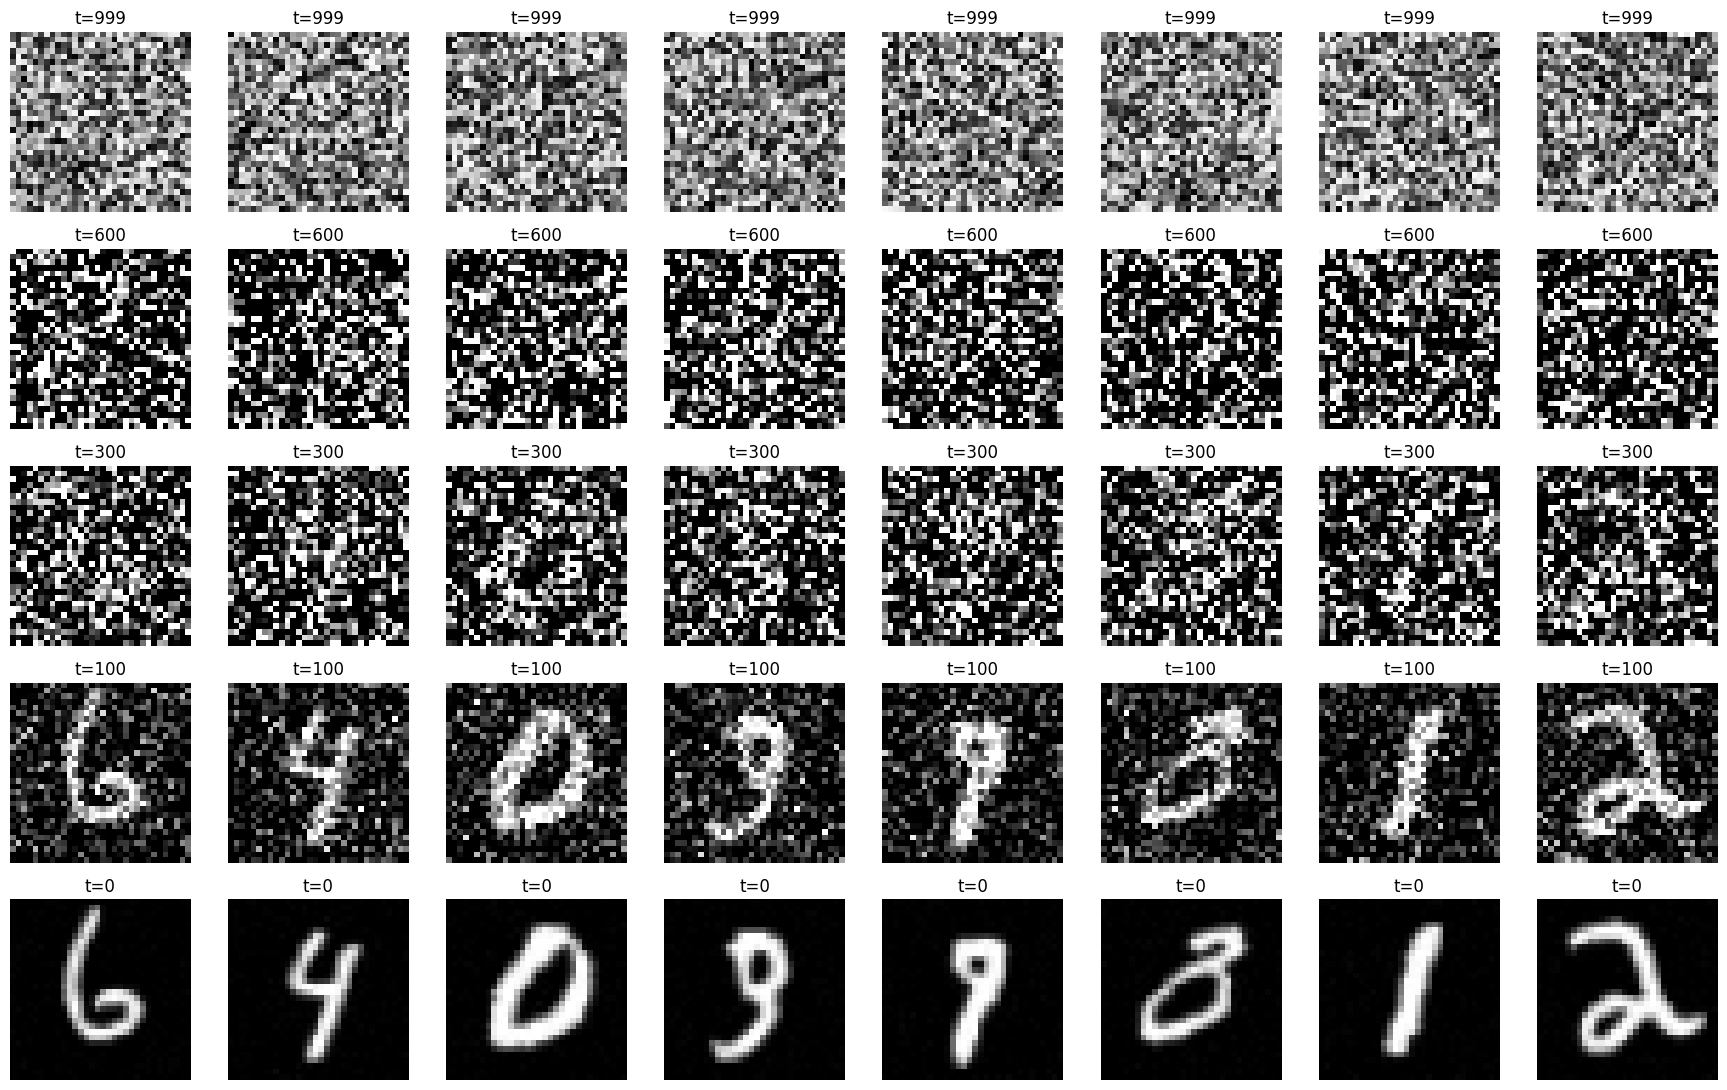

In [22]:
model_ddpm_repaint.eval()
x_test,_=next(iter(test_loader))
x_test=x_test.to(device)
num_images=8
x3=x_test[:num_images]
timesteps_reverse_shown= [999,600,300,100,0]
num_rows=len(timesteps_reverse_shown)

fig2, axes2 = plt.subplots(num_rows,num_images, figsize=(2.2*num_images, 2.2*num_rows))

with torch.no_grad():
    xt=torch.rand_like(x3)

    for step in reversed(range(scheduler.betas.shape[0])):
        if step in timesteps_reverse_shown:
            row= timesteps_reverse_shown.index(step)
            for i in range(num_images):
                axes2[row,i].imshow(xt[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1) 
                axes2[row,i].axis("off")
                axes2[row,i].set_title(f"t={step}")
        t=torch.full((x3.shape[0],),step, device=device, dtype= torch.long)
        predicted_noise=model_ddpm_repaint(xt,t)
        xt,x0_predicted=scheduler.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()         

In [25]:
def sample_repaint(model,scheduler,x0,mask,U=5):
    with torch.no_grad():
        model.eval()
        B=x0.shape[0]
        T=scheduler.betas.shape[0]
        mask=mask.to(x0.device)
        xt=torch.rand_like(x0)

        for step in reversed(range(T)):
            for u in range(U):
                t=torch.full((B,),step,device=device,dtype=torch.long)
                predicted_noise=model(xt,t)
                xt_unknown,x0_pred=scheduler.reverse_sampling_step(xt,predicted_noise,step)
                if step>0:
                    gaussian_noise=torch.rand_like(x0)
                    t_prev=torch.full((B,),step-1,device=device,dtype=torch.long)
                    x_known=scheduler.add_noise(x0,gaussian_noise,t_prev)
                else:
                    x_known=x0
                xt_prev=mask*x_known +(1.0-mask)*xt_unknown
                if(u<U-1) and (step>0):
                    z=torch.rand_like(xt_prev)
                    xt=torch.sqrt(scheduler.alphas[step]) * xt_prev +torch.sqrt(scheduler.betas[step])*z
                else: xt=xt_prev
        return xt.clamp(0.0,1.0)                    

In [26]:
model_ddpm_repaint.eval()
with torch.no_grad():
    x_test,_=next(iter(test_loader))
    x_test=x_test.to(device)
    num_images=8
    x4=x_test[:num_images]
    masks= random_circle_mask(x4,min_radius=6.0, max_radius=8.0, min_pixel_value=0.5)
    masked_image=x4*masks
    repaint_samples= sample_repaint(model_ddpm_repaint,scheduler,x4,masks,U=5)

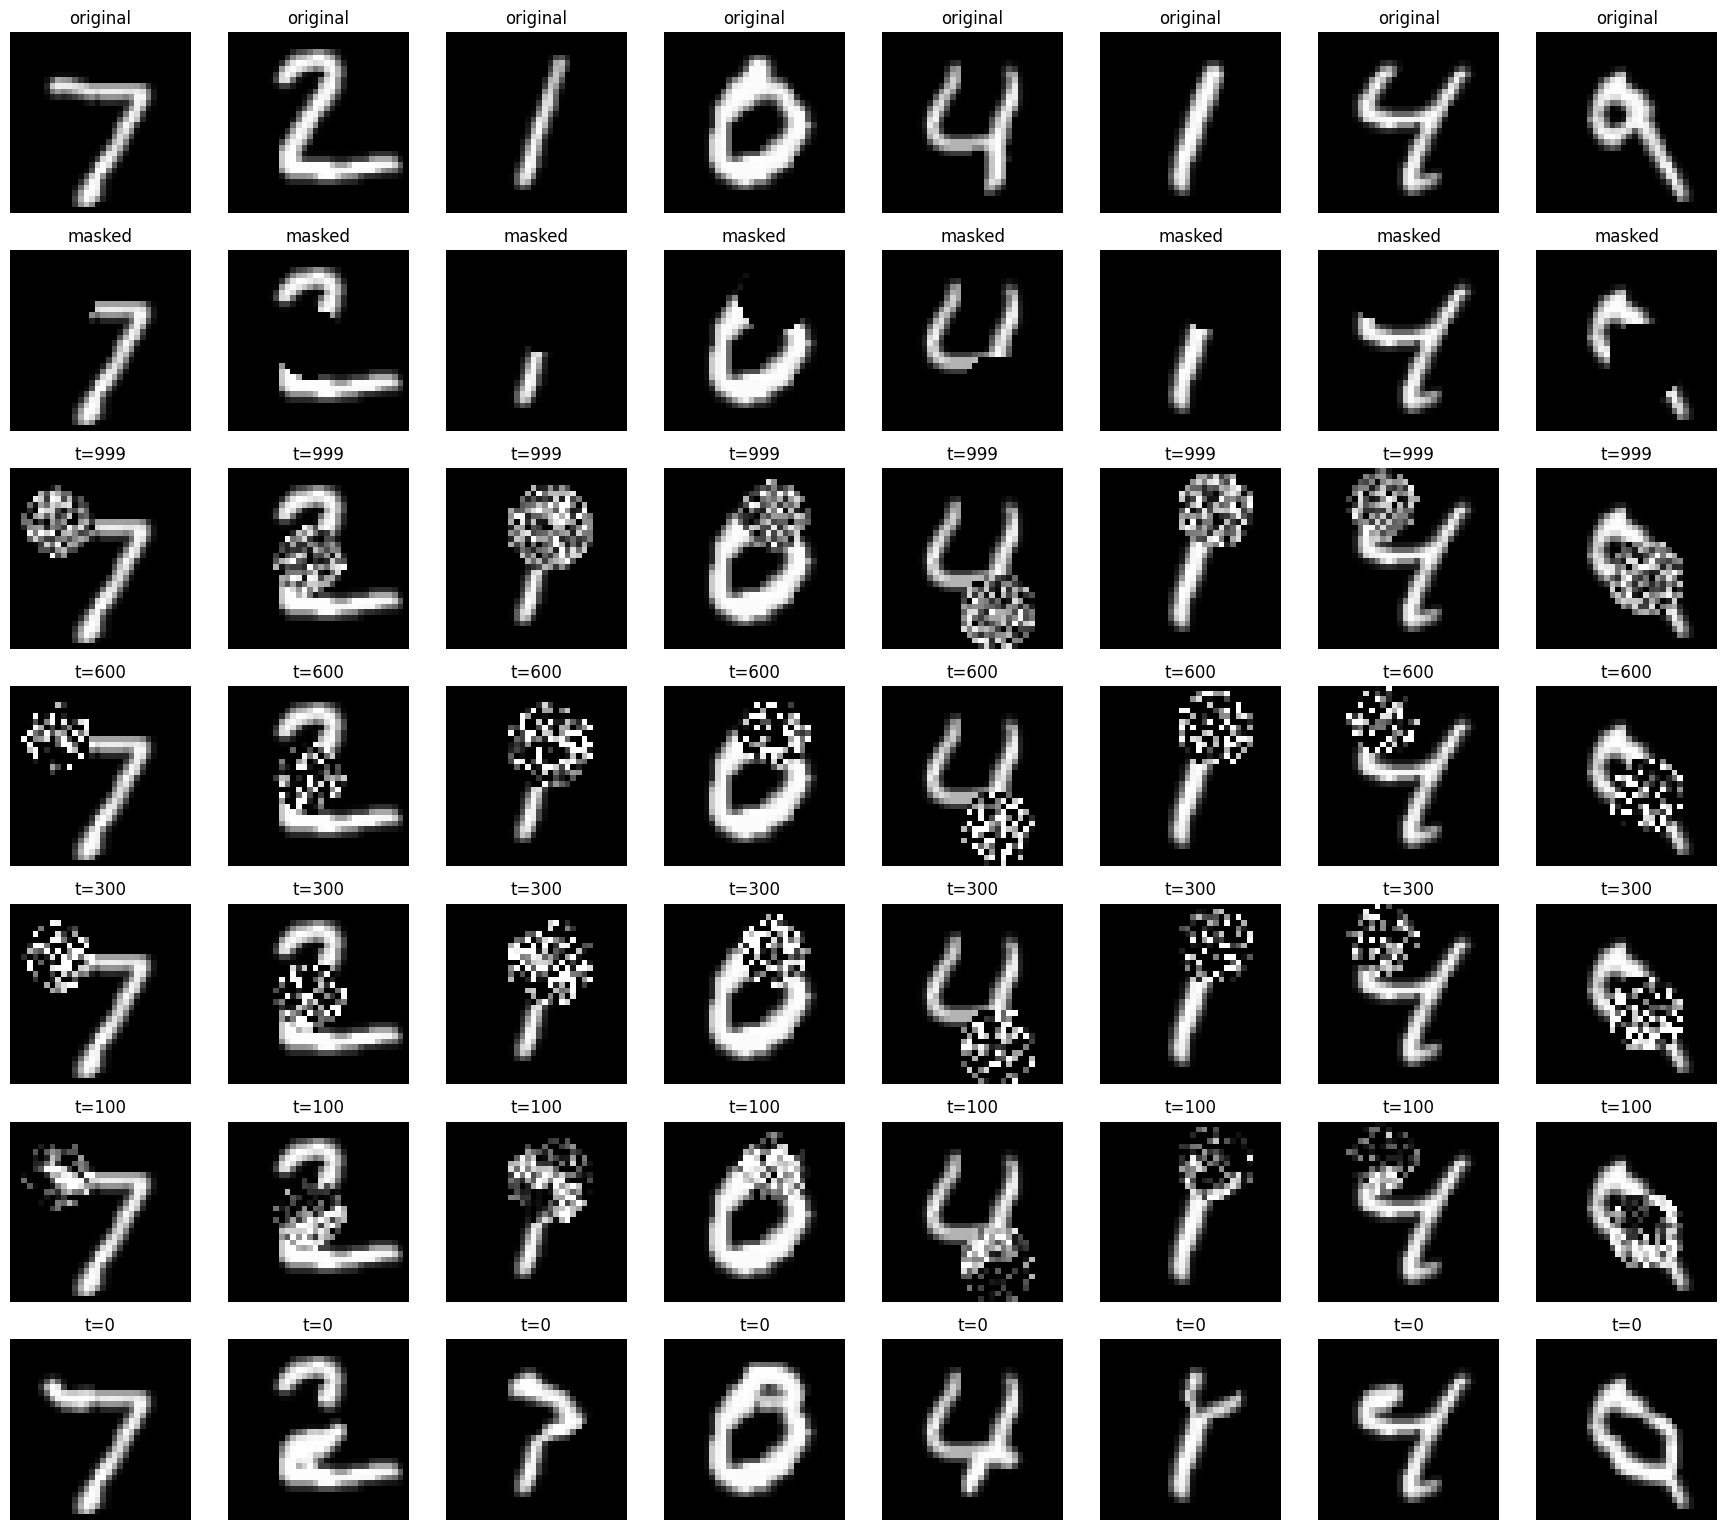

In [34]:
model_ddpm_repaint.eval()
x_test,_=next(iter(test_loader))
x_test=x_test.to(device)
num_images=8
x4=x_test[:num_images]
masks=random_circle_mask(x4,min_radius=6.0,max_radius=8.0, min_pixel_value=0.5)
masked_image=x4*masks
timesteps_reverse_shown= [999,600,300,100,0]
num_rows=2+len(timesteps_reverse_shown)
fig3, axes3 = plt.subplots(num_rows,num_images, figsize=(2.2*num_images, 2.2*num_rows))

with torch.no_grad():
    xt=torch.rand_like(x3)
    for i in range (num_images):
        axes3[0,i].imshow(x4[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1)
        axes3[0,i].axis("off")
        axes3[0,i].set_title("original")
        axes3[1,i].imshow(masked_image[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1)
        axes3[1,i].axis("off")
        axes3[1,i].set_title("masked")

    B=x4.shape[0] 
    T=scheduler.betas.shape[0]   
    U=1
    xt=torch.rand_like(x4)

    for step in reversed(range(scheduler.betas.shape[0])):
        for u in range(U):
            t=torch.full((B,),step, device=device, dtype= torch.long)
            predicted_noise=model_ddpm_repaint(xt,t)
            xt_unknown,x0_predicted=scheduler.reverse_sampling_step(xt,predicted_noise,step)
            if step>0:
                    gaussian_noise=torch.rand_like(x4)
                    t_prev=torch.full((B,),step-1,device=device,dtype=torch.long)
                    x_known=scheduler.add_noise(x4,gaussian_noise,t_prev)
            else:
                x_known=x4
            xt_prev=masks*x_known +(1.0-masks)*xt_unknown
            if(u<U-1) and (step>0):
                    z=torch.rand_like(xt_prev)
                    xt=torch.sqrt(scheduler.alphas[step-1]) * xt_prev +torch.sqrt(scheduler.betas[step-1])*z
            else: xt=xt_prev
        if step in timesteps_reverse_shown:
            row= timesteps_reverse_shown.index(step)+2
            reconstructed=masks*x4+(1.0-masks)*xt
            reconstructed=reconstructed.clamp(0.0,1.0)
            for i in range(num_images):
                axes3[row,i].imshow(reconstructed[i,0].detach().cpu(), cmap="gray",vmin=0,vmax=1) 
                axes3[row,i].axis("off")
                axes3[row,i].set_title(f"t={step}")
        
plt.tight_layout()
plt.show()    